# SMILE2pGeometry: SMILE-2+ の形状

Geant4 の中に SMILE-2+ の検出器(TPC のガス、圧力容器、HA のシンチ、アンチ、架台、気球のゴンドラなど)を組み立てます。
チェーンの最初のモジュールで、設定ファイルの `detector` の節です。

| | |
| --- | --- |
| SMILE_tool_box | `SMILE_2p_Geo`(sim.mac の `GeometryType`, `GeometryCADdir`, `HA_PositionFile`, `TPC_Gas_Pressure`) |
| ソース | `simulation_source/modules/SMILE2pGeometry/`(形状を組み立てるコードは `simulation_source/vendor/smile2p_geo/` に SMILE_tool_box のものをそのまま取り込み) |
| 基底クラス | anlgeant4 の `VANLGeometry` |

## 1. 何をするか

形状は次の 2 種類の組み合わせです(`../../../0_Introduction/README.md` の 3 節)。

1. `.mqo` の 3 次元メッシュ(`geometry_dir` の中): TPC のガス、圧力容器、容器の中の構造物、架台、アンチ、空気、
   flight のときはゴンドラなど。
2. コードで書いた立体: HA のシンチのピクセル(8 × 8 × 6 PMT × 18 台)。位置と向きは `ha_position_file` から読む。

| `geometry_type` | 中身 |
| --- | --- |
| `flight` | 気球実験の形(ゴンドラ `bCALET.mqo`, `gondola.mqo` を含む) |
| `ground` | 地上の較正の形(架台 `etcc_base_no_battery.mqo` が要るが `SMILE_tool_box_v2.20/data` に無いので注意) |
| `no_vessel` | 圧力容器なし |

ガスの組成と密度は `gas_pressure` から決まります(`vendor/` の `SMILE_Material`)。

## 2. パラメータ

| パラメータ | 型 | 既定値(C++) | この設定の値 | 単位 | 説明 |
| --- | --- | --- | --- | --- | --- |
| `geometry_dir` | string | SMILE_2p_Geo | {sim_data}/SMILE_2p_Geo |  | SMILE-2+ の形状のファイル(*.mqo)のディレクトリ |
| `geometry_type` | string | ground | flight |  | flight(気球のゴンドラ付き)/ ground(地上の較正)/ no_vessel |
| `ha_position_file` | string | HAs.pos | …/HA_Parameters_20190403_position_only/HAs.pos |  | HA の位置と向きのファイル(HAs.pos) |
| `gas_pressure` | double | 2.0 | 2.0 | atm | TPC のガスの圧力 [atm] |
| `surface_check` | bool | false | (設定に無い: 既定値) |  | 立体の重なりを Geant4 で調べる(anlgeant4 の `VANLGeometry` のパラメータ) |
パラメータは設定ファイル `config/simulation/smile2p_flight_parma_thermal_neutron_d10_raw.json` の `detector.parameters` に書きます
(書き方は `config/README.md`)。1 回だけ変えて試すときは `run_sim.py ... --set detector.gas_pressure=1.0` で上書きします。
「既定値(C++)」は設定ファイルに書かなかったときの値です。

## 3. ほかのモジュールとのやり取り

ほかのモジュールに値を渡す関数はありません。作った形状は Geant4 の中にあり、`Geant4Body` が使います。
後ろのモジュールは **立体の名前** で検出器を区別します(`EdepPickUp` の `tpc_volume = "TPC_detectable"`、
シンチは名前に `scinti` を含む `scinti_<bottom|side>_<HA 番号>_<PMT>_<ピクセル>`、アンチは `anti`)。

## 4. 確かめる

エネルギーを落としたステップの位置を描くと、形状のうち検出器の部分が見えます(`EdepPickUp` の記録から)。

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT
ROOT.gROOT.SetBatch(True)

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_sim.py").exists())
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec
CONFIG = "smile2p_flight_parma_thermal_neutron_d10_raw"
cfg = ec.load_sim(CONFIG)
# 1_DataIO/DataIO_example.ipynb の出力(d10 の熱中性子、100 万個、seed 1)を使う
SIM = REPO / "tutorials_simulation" / "cache" / "d10_seed1_1M"
EDEP, RAW = SIM / "edep.root", SIM / "raw"
assert EDEP.exists(), "先に ../../DataIO_example.ipynb を実行してください"

def flat(column):
    # RDataFrame.AsNumpy() の vector 型の列 -> 全イベントをつないだ 1 次元の numpy 配列
    return np.concatenate([np.asarray(v) for v in column]) if len(column) else np.array([])

TPC のステップ: 390983  シンチのステップ: 1301265
TPC のガス: x -150〜150, y -150〜150, z 28〜328 mm


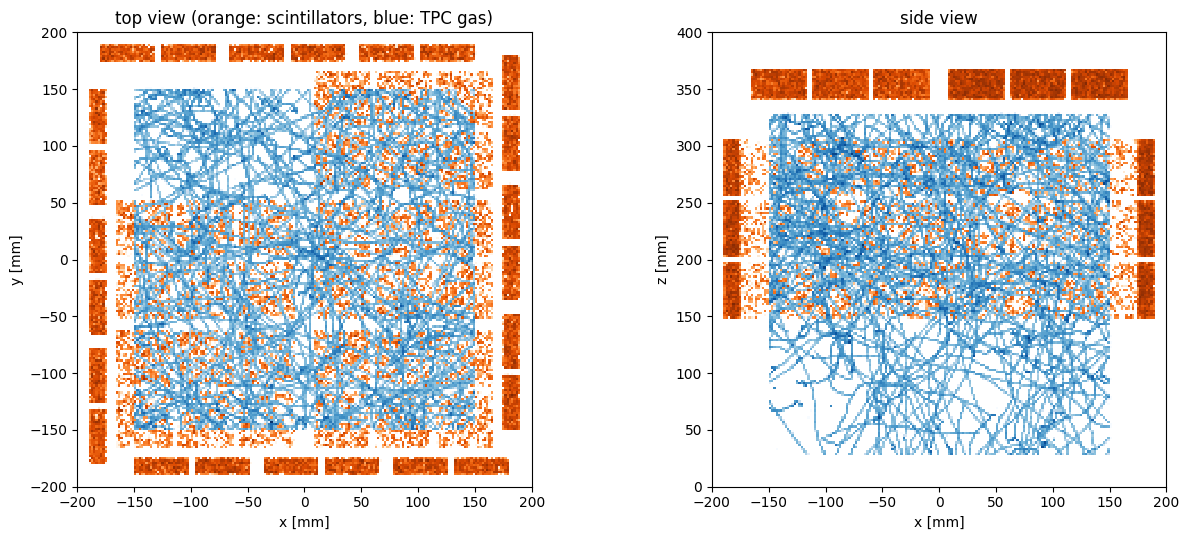

In [2]:
d = ROOT.RDataFrame("edep", str(EDEP)).AsNumpy(["tpc_x", "tpc_y", "tpc_z", "sci_x", "sci_y", "sci_z"])
tx, ty, tz = (flat(d[k]) for k in ["tpc_x", "tpc_y", "tpc_z"])
sx, sy, sz = (flat(d[k]) for k in ["sci_x", "sci_y", "sci_z"])
print("TPC のステップ:", len(tx), " シンチのステップ:", len(sx))
print(f"TPC のガス: x {tx.min():.0f}〜{tx.max():.0f}, y {ty.min():.0f}〜{ty.max():.0f}, z {tz.min():.0f}〜{tz.max():.0f} mm")

from matplotlib.colors import LogNorm
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (u1, v1, u2, v2, lv) in zip(ax, [(sx, sy, tx, ty, "y"), (sx, sz, tx, tz, "z")]):
    rng = [[-200, 200], [-200, 200]] if lv == "y" else [[-200, 200], [0, 400]]
    a.hist2d(u1, v1, bins=200, range=rng, cmap="Oranges", norm=LogNorm(), cmin=1)    # シンチ
    a.hist2d(u2, v2, bins=200, range=rng, cmap="Blues", norm=LogNorm(), cmin=1)      # TPC
    a.set_xlabel("x [mm]"); a.set_ylabel(f"{lv} [mm]"); a.set_aspect("equal")
ax[0].set_title("top view (orange: scintillators, blue: TPC gas)"); ax[1].set_title("side view")
fig.tight_layout(); plt.show()

- 青が TPC のガス(一辺 300 mm、z = 28〜328 mm)、橙が HA のシンチです(エネルギーを落としたステップの数、対数の色)。底面の HA(z が大きい側)と側面の HA が TPC を囲んでいます。
- 上から見た図の左上(x, y) = (−87, 114) mm の底面の HA が抜けているのは、HA 7 の PMT がすべて `HA_OFF.dat` で使わないことになっていて、
  `EdepPickUp` がそのステップを捨てるためです(`../4_EdepPickUp/`)。
- 座標系は実データと同じです(`../../../../tutorials_caldata/0_Introduction/`)。z はドリフトの方向で、線源の較正では z の負の側に線源を置きます。

## 5. GDML に書き出して描く

組み立てた形状は、anlgeant4 の `WriteGDML` で GDML のファイルに書き出せます(`run_sim.py --gdml <ファイル>`)。
GDML は Geant4 の形状を書く XML の形式で、`.mqo` のメッシュは三角形の面の集まり(`tessellated`)として入ります。
1 つのファイルに形状がまとまるので、中身を確かめたり、ほかのツール(ROOT の `TGeoManager::Import` など)で読んだりできます。

```bash
cd run_script
python3 run_sim.py smile2p_flight_parma_thermal_neutron_d10 -n 1 -o /tmp/edep.root --gdml smile2p_flight.gdml   # 形状だけ(一次粒子 1 個)
python3 draw_geometry.py smile2p_flight.gdml -o images/                                                  # 図を書き出す
```

`draw_geometry.py` は GDML を Geant4 に読み込み(anlgeant4 の `ReadGDML`)、Geant4 の可視化を画面無しで使って
(`TSG_OFFSCREEN`、EricaSimPy の `GeometryImage`)PNG の図を書きます。色は立体の名前で決めています(`draw_geometry.py` の `COLOURS`)。

| 色 | 立体 |
| --- | --- |
| 緑 | HA のシンチ(ピクセルとそれを包む反射材) |
| 濃い灰 | HA の PMT(H8500) |
| 水色(半透明) | TPC のドリフト領域(`TPC_detectable`) |
| 黄土 | ドリフトケージ |
| 橙 | アンチ、µ-PIC |
| 薄い灰 | 圧力容器、ゴンドラ |

In [3]:
import subprocess
from IPython.display import Image, display
GEO = REPO / "tutorials_simulation" / "cache" / "geometry"
GDML = GEO / "smile2p_flight.gdml"
if not GDML.exists():
    GEO.mkdir(parents=True, exist_ok=True)
    subprocess.run([sys.executable, str(REPO / "run_script" / "run_sim.py"), CONFIG.replace("_raw", ""), "-n", "1",
                    "-o", str(GEO / "edep_1.root"), "--gdml", str(GDML)], capture_output=True, text=True,
                   cwd=REPO / "run_script").check_returncode()
print(f"{GDML.name}: {GDML.stat().st_size / 1e6:.0f} MB")
if not (GEO / "smile2p_flight_top.png").exists():
    subprocess.run([sys.executable, str(REPO / "run_script" / "draw_geometry.py"), str(GDML), "-o", str(GEO)],
                   capture_output=True, text=True, cwd=REPO / "run_script").check_returncode()

smile2p_flight.gdml: 54 MB


**外から見た形**(flight): 圧力容器と、気球のゴンドラの脚、バラスト。z 軸は下向きなので、図の上が −z(空の側)です。

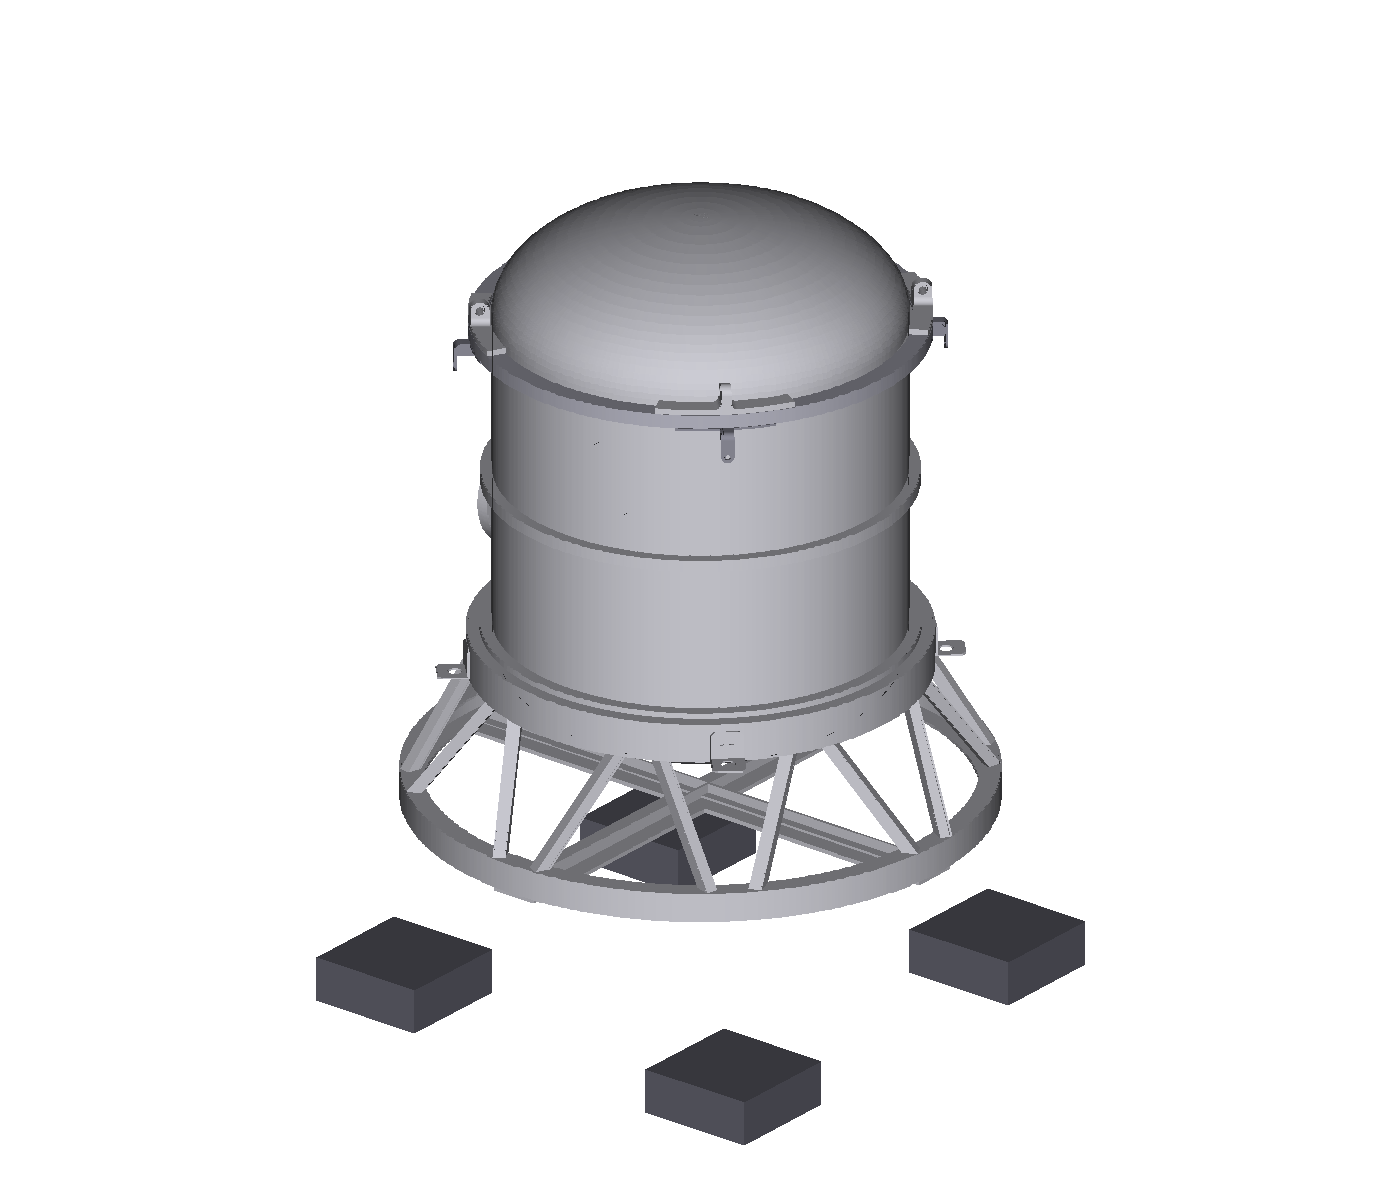

In [4]:
display(Image(str(GEO / "smile2p_flight_outside.png"), width=600))

**検出器**: ゴンドラ、圧力容器、アンチ、支えの構造を隠したもの。TPC(ドリフト領域、ドリフトケージ、上の µ-PIC)の側面と底面を HA が囲んでいます。

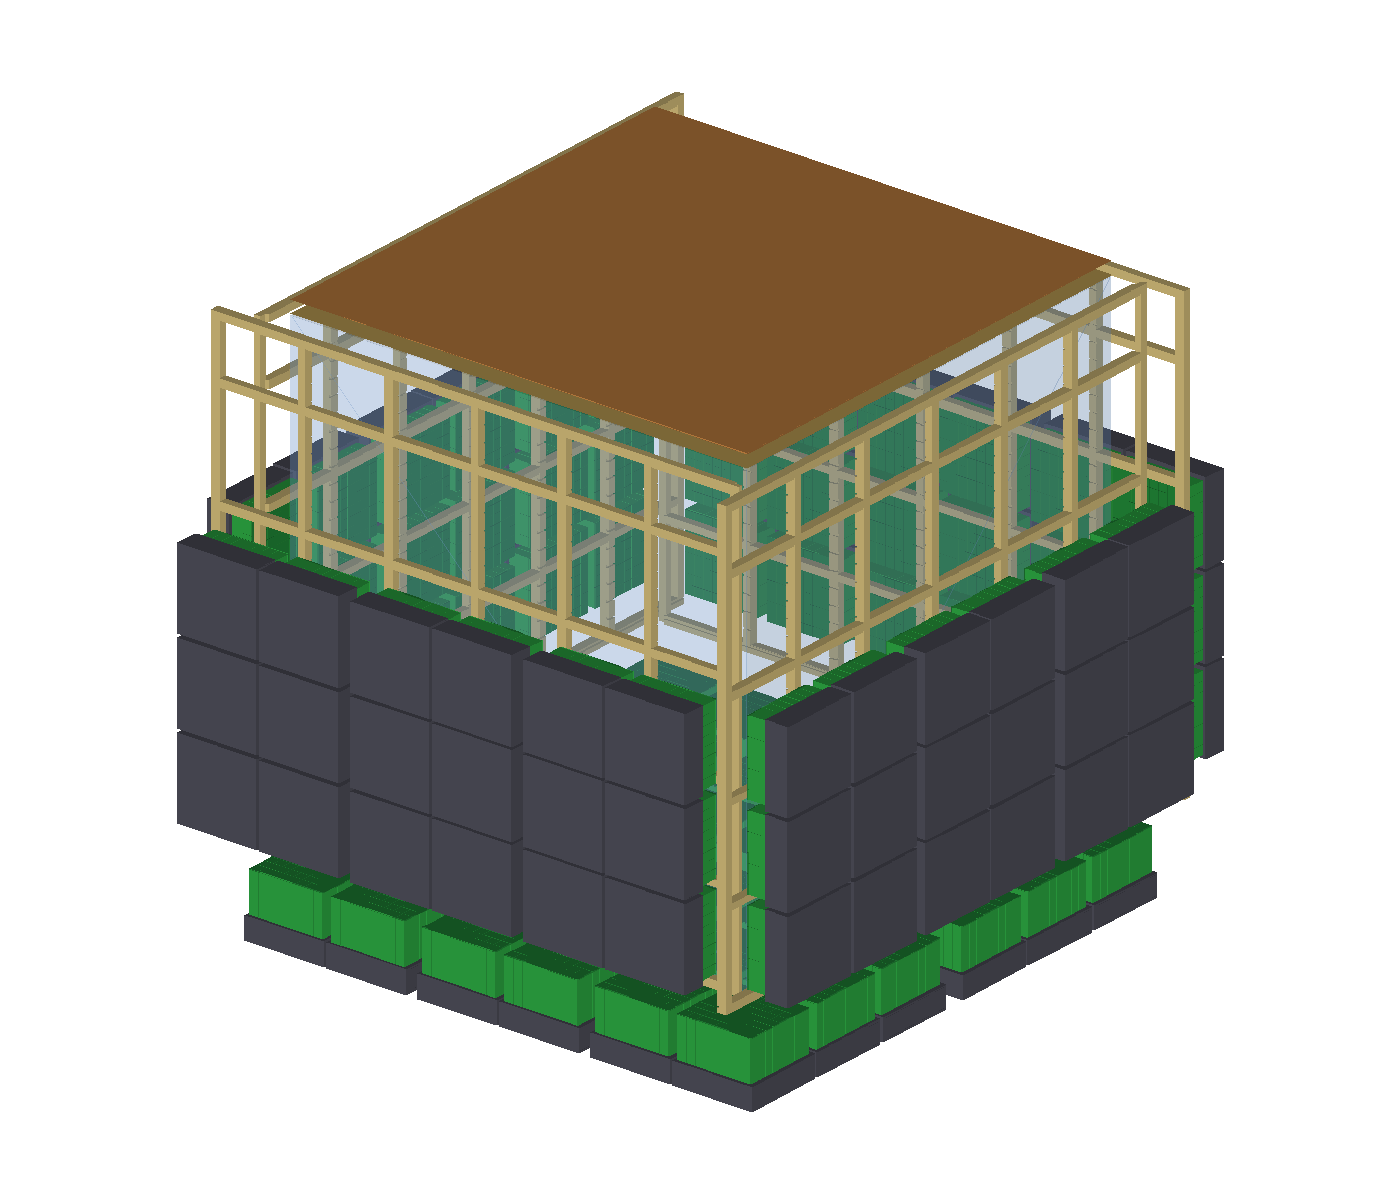

In [5]:
display(Image(str(GEO / "smile2p_flight_detector.png"), width=600))

**上から見た HA の並び**(TPC の中身も隠したもの): 底面の HA 6 台(1 台に PMT 6 本)と側面の HA 12 台。
図の右が +x、下が +y です(z が下向きの座標を上から見ているため。HA 1 = (x, y) = (87, 114) mm が右下の底面の HA)。
4 節の図と比べると、ここでは HA 7(左下)もあります。形状には 18 台すべてがあり、使っていない PMT のエネルギー損失を捨てるのは `EdepPickUp` です。

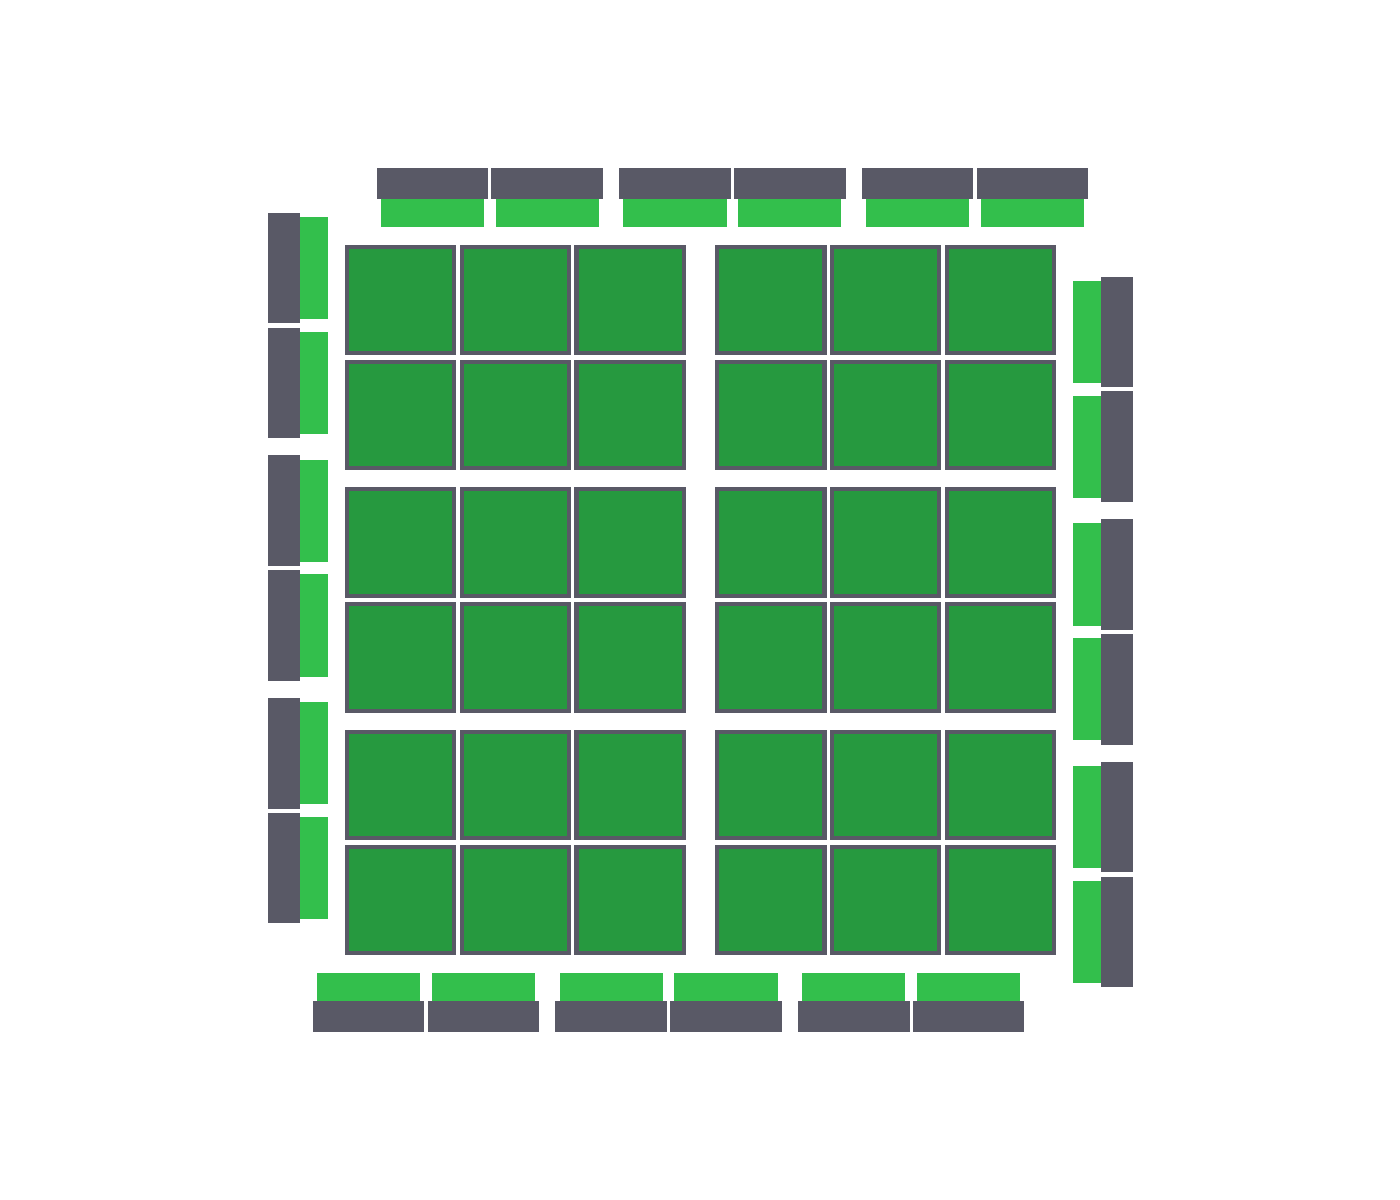

In [6]:
display(Image(str(GEO / "smile2p_flight_top.png"), width=600))